In [1]:
import random

from setuptools.compat.py311 import shutil_rmtree
import torch
import torch.nn as nn
import torchvision

from torchvision import transforms
from torch.utils.data import Dataset

from tqdm.auto import tqdm
from pathlib import Path
from torchinfo import summary
from PIL import Image
from finished_stuff.going_modular import model_saver, data_setter_loader, trainer, plot_loss_curves


/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
device

'cuda'

In [4]:
train_dir = "../data/food_20_percent/train"
test_dir = "../data/food_20_percent/test"

## MAKING AN EFFICIEENTNETB2 MODEL

In [13]:
eff_b2_model_weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT
eff_b2_model_transform = eff_b2_model_weights.transforms()
eff_b2_model = torchvision.models.efficientnet_b2(weights=eff_b2_model_weights)
for param in eff_b2_model.parameters():
    param.requires_grad = False

eff_b2_model.classifier

Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=1408, out_features=1000, bias=True)
)

In [14]:
eff_b2_model.classifier = nn.Sequential(
    nn.Dropout(p=0.3,inplace=True),
    nn.Linear(in_features=1408, out_features=3)
)

In [15]:
summary(eff_b2_model,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 3]               --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1408, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    (864)                False
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    (64)                 False
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 1

###  Creating a function to make an EffNetB2 feature extractor

In [5]:
def create_eff_b2_model (num_classes):
    eff_b2_model_weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT

    eff_b2_model_transform = eff_b2_model_weights.transforms()

    eff_b2_model = torchvision.models.efficientnet_b2(weights=eff_b2_model_weights)

    for param in eff_b2_model.parameters():
        param.requires_grad = False

    eff_b2_model.classifier = nn.Sequential(
    nn.Dropout(p=0.3,inplace=True),
    nn.Linear(in_features=1408, out_features=num_classes))

    return eff_b2_model , eff_b2_model_transform

In [17]:
#try it
eff_b2_model , eff_b2_model_transform = create_eff_b2_model(num_classes=3)

summary(eff_b2_model,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 3]               --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1408, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    (864)                False
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    (64)                 False
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 1

### MAKING THE DATA FOR THE EFFIECIENTNETB2 MODEL

In [18]:
train_dataloader_effB2 , test_dataloader_effB2 , classes = data_setter_loader.data_setter_loader(train_dir,
                                                                                                 test_dir,
                                                                                                 eff_b2_model_transform,
                                                                                                 32,
                                                                                                 4)
classes

['pizza', 'steak', 'sushi']

In [19]:
# training the model
optimizer = torch.optim.Adam(eff_b2_model.parameters(),lr=0.001)
loss_fn = nn.CrossEntropyLoss()
eff_b2_results = trainer.training_fn(eff_b2_model,
                                     train_dataloader_effB2,
                                     test_dataloader_effB2,
                                     loss_fn,
                                     optimizer,
                                     10,
                                     device)

 10%|█         | 1/10 [00:14<02:10, 14.54s/it]

Epoch: 1 | Train loss: 0.9846 | Train acc: 54.1667 | Test loss: 0.7663 | Test acc: 82.1591


 20%|██        | 2/10 [00:26<01:43, 12.95s/it]

Epoch: 2 | Train loss: 0.7465 | Train acc: 75.6250 | Test loss: 0.6130 | Test acc: 91.9886


 30%|███       | 3/10 [00:38<01:28, 12.59s/it]

Epoch: 3 | Train loss: 0.5743 | Train acc: 88.7500 | Test loss: 0.5136 | Test acc: 95.0000


... (10 outputs left out)

 90%|█████████ | 9/10 [01:47<00:11, 11.67s/it]

Epoch: 9 | Train loss: 0.3763 | Train acc: 85.6250 | Test loss: 0.3010 | Test acc: 94.3750


100%|██████████| 10/10 [01:59<00:00, 11.90s/it]

Epoch: 10 | Train loss: 0.3125 | Train acc: 94.3750 | Test loss: 0.3022 | Test acc: 95.9659


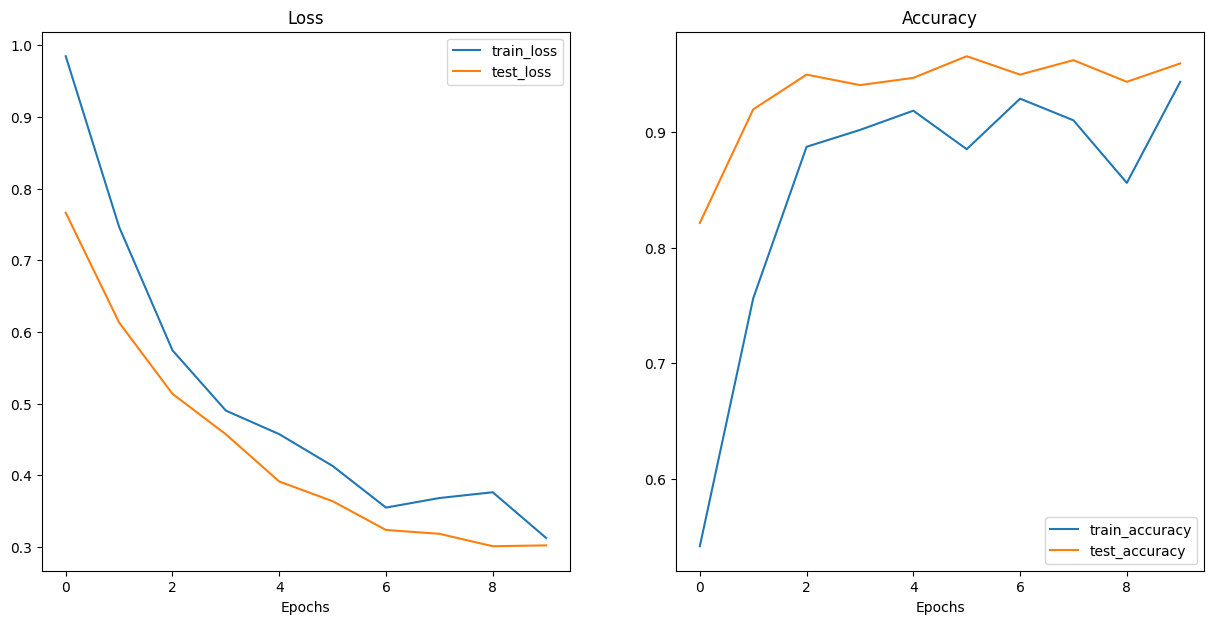

In [21]:
plot_loss_curves.plot_loss_curves(eff_b2_results)

In [25]:
model_saver.model_saver(eff_b2_model, "../../models", "09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth")

saving model to ..\models\09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth


### INSPECTING THE SIZE

In [30]:
eff_net_b2_model_size = Path("./models/09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth").stat().st_size / (1024*1024)
print(f"size_eff_net_b2_model: {eff_net_b2_model_size:.2f} MB")

size_eff_net_b2_model: 29.85 MB


## COLLECTING THE DATA ON THE MODEL

In [32]:
eff_b2_model_sum_param = sum(torch.numel(param) for param in eff_b2_model.parameters())
eff_b2_model_sum_param

7705221

In [107]:
eff_b2_model_stats ={"ACCURACY" : round(eff_b2_results["test_acc"][-1]*100,3),
                     "LOSS" : round(eff_b2_results["test_loss"][-1],3),
                     "SIZE" : round(eff_net_b2_model_size,2),
                     "PARAM" : round(eff_b2_model_sum_param,2)}
eff_b2_model_stats

{'ACCURACY': 95.966, 'LOSS': 0.302, 'SIZE': 29.85, 'PARAM': 7705221}

# MAKING THE EfficientNet_V2_S MODEL

In [49]:
EfficientNet_V2_S_weights = torchvision.models.EfficientNet_V2_S_Weights.DEFAULT
EfficientNet_V2_S_transform = EfficientNet_V2_S_weights.transforms()
EfficientNet_V2_S_model = torchvision.models.efficientnet_v2_s(weights=EfficientNet_V2_S_weights)

summary(EfficientNet_V2_S_model,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to C:\Users\seifm/.cache\torch\hub\checkpoints\efficientnet_v2_s-dd5fe13b.pth
100%|██████████| 82.7M/82.7M [00:40<00:00, 2.16MB/s]


Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 1000]            --                   True
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1280, 7, 7]      --                   True
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 24, 112, 112]    --                   True
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 24, 112, 112]    648                  True
│    │    └─BatchNorm2d (1)                                  [1, 24, 112, 112]    [1, 24, 112, 112]    48                   True
│    │    └─SiLU (2)                                         [1, 24, 112, 112]    [1, 24, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 24, 112, 112]    [1, 24, 112,

In [52]:
EfficientNet_V2_S_model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

In [6]:
def create_EfficientNet_V2_S (num_classes):
    weights = torchvision.models.EfficientNet_V2_S_Weights.DEFAULT
    transform = weights.transforms()
    model = torchvision.models.efficientnet_v2_s(weights=weights)
    for param in model.parameters():
        param.requires_grad = False
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.2, inplace=True),
        nn.Linear(in_features=1280, out_features=num_classes, bias=True)
        )
    return model, transform

In [54]:
EfficientNet_V2_S_model , EfficientNet_V2_S_transform = create_EfficientNet_V2_S(len(classes))
EfficientNet_V2_S_transform

ImageClassification(
    crop_size=[384]
    resize_size=[384]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [55]:
summary(EfficientNet_V2_S_model,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 3]               --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1280, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 24, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 24, 112, 112]    (648)                False
│    │    └─BatchNorm2d (1)                                  [1, 24, 112, 112]    [1, 24, 112, 112]    (48)                 False
│    │    └─SiLU (2)                                         [1, 24, 112, 112]    [1, 24, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 24, 112, 112]    [1, 2

In [56]:
EfficientNet_V2_S_train_dataloader , EfficientNet_V2_S_test_dataloader , classes = data_setter_loader.data_setter_loader(train_dir, test_dir, EfficientNet_V2_S_transform, 32, 4)
classes

['pizza', 'steak', 'sushi']

In [58]:
optimizer = torch.optim.Adam(EfficientNet_V2_S_model.parameters(),lr=0.001)
loss_fn = nn.CrossEntropyLoss()
EfficientNet_V2_S_results = trainer.training_fn(EfficientNet_V2_S_model,
                                                EfficientNet_V2_S_train_dataloader,
                                                EfficientNet_V2_S_test_dataloader,
                                                loss_fn,
                                                optimizer,
                                                10,
                                                device)

 10%|█         | 1/10 [00:14<02:14, 14.99s/it]

Epoch: 1 | Train loss: 0.9905 | Train acc: 56.4583 | Test loss: 0.7889 | Test acc: 77.6136


 20%|██        | 2/10 [00:29<01:56, 14.52s/it]

Epoch: 2 | Train loss: 0.7307 | Train acc: 79.7917 | Test loss: 0.5840 | Test acc: 95.3409


 30%|███       | 3/10 [00:43<01:40, 14.33s/it]

Epoch: 3 | Train loss: 0.5702 | Train acc: 88.7500 | Test loss: 0.5123 | Test acc: 95.3409


... (10 outputs left out)

 90%|█████████ | 9/10 [02:07<00:14, 14.02s/it]

Epoch: 9 | Train loss: 0.3275 | Train acc: 90.2083 | Test loss: 0.3014 | Test acc: 94.4318


100%|██████████| 10/10 [02:21<00:00, 14.17s/it]

Epoch: 10 | Train loss: 0.3016 | Train acc: 91.4583 | Test loss: 0.2901 | Test acc: 95.0568


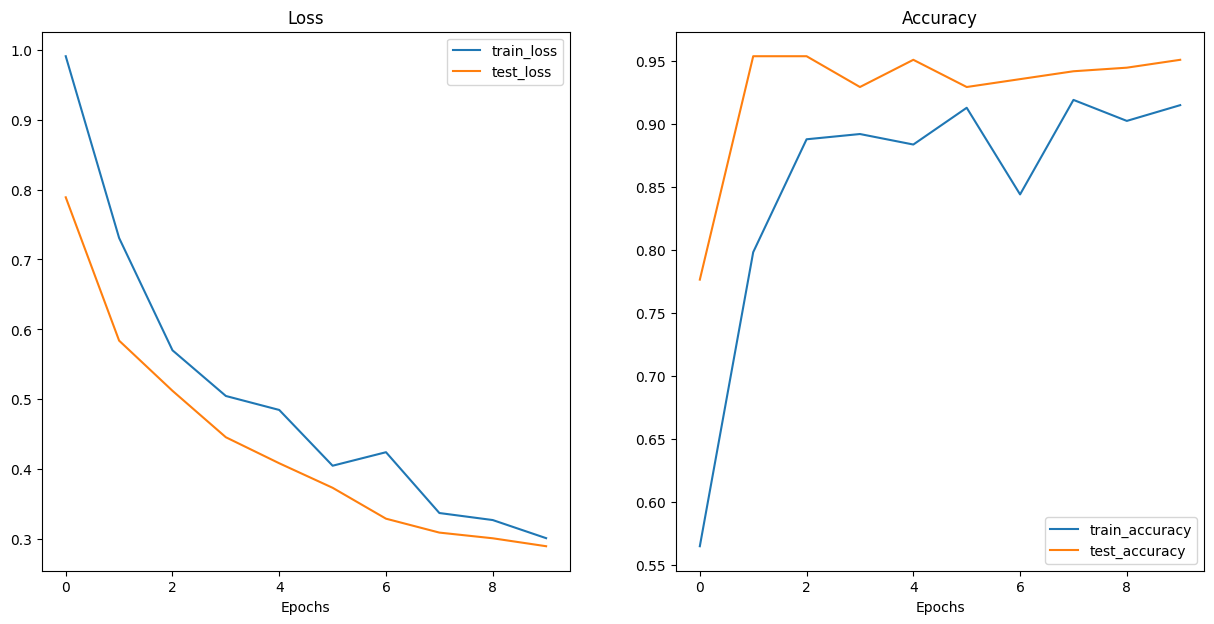

In [59]:
#lets check the model
plot_loss_curves.plot_loss_curves(EfficientNet_V2_S_results)

In [64]:
#save the model
model_saver.model_saver(EfficientNet_V2_S_model, "./models", "09_EfficientNet_V2_S_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth")

saving model to models\09_EfficientNet_V2_S_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth


In [65]:
#lets check the size of the model
EfficientNet_V2_S_model_size = Path("./models/09_EfficientNet_V2_S_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth").stat().st_size / (1024*1024)
print(f"size of EfficientNet_V2_S : {EfficientNet_V2_S_model_size:.2f} MB")

size of EfficientNet_V2_S : 77.88 MB


In [66]:
# GET SUM PARA
EfficientNet_V2_S_sum_param = sum(torch.numel(param) for param in EfficientNet_V2_S_model.parameters())
EfficientNet_V2_S_sum_param

20181331

In [67]:
#make a dic
EfficientNet_V2_S_stats = {"ACCURACY" : round(EfficientNet_V2_S_results["test_acc"][-1]*100,3),
                           "LOSS": round(EfficientNet_V2_S_results["test_loss"][-1],3),
                           "SIZE": round(EfficientNet_V2_S_model_size,2),
                           "PARAM": round(EfficientNet_V2_S_sum_param,2)}
EfficientNet_V2_S_stats

{'ACCURACY': 95.057, 'LOSS': 0.29, 'SIZE': 77.88, 'PARAM': 20181331}

# *5. Making predictions with our trained models and timing them*
**Our goal:**
* Performs well (95%+ test accuracy)
* Fast (30+FPS)

**To test criteria two:**
* Loop through test images
* Time how long each model takes to make a prediction on the image
Let's work towards making a function called pred_and_store() to do so.

In [7]:
#GETTING THE TEST DATA PATHS
test_data_paths = list(Path(test_dir).glob("*/*.jpg"))
test_data_paths[:5]

[PosixPath('../data/food_20_percent/test/steak/40947.jpg'),
 PosixPath('../data/food_20_percent/test/steak/595836.jpg'),
 PosixPath('../data/food_20_percent/test/steak/730464.jpg'),
 PosixPath('../data/food_20_percent/test/steak/3757027.jpg'),
 PosixPath('../data/food_20_percent/test/steak/1902895.jpg')]

In [8]:
# CREATE A FUNCTION THAT MAKES UP A PREDICITONS LIST THAT FROM THE TEST PATH WHERE IT GIVES [INFO] ON EACH PREDICITON IN FORM OF A DICTIONARY IN THE LIST
def model_test_preds_stats(paths:list,
                           model,
                           transform,
                           class_names,
                           device):
    pred_stats = []
    for path in tqdm(paths):
        # make a dic
        pred_dic = {}
        # add at dic
        pred_dic["image_path"] = str(path)
        class_name = path.parent.stem
        pred_dic["class_name"] = class_name
        # start time
        start_time = timer()
        img = Image.open(path)
        transformed_image = transform(img).unsqueeze(0).to(device)
        model = model.to(device)
        model.eval()
        with torch.inference_mode():
            pred_logits = model(transformed_image)
            pred_probs = torch.softmax(pred_logits, dim=1)
            pred_label = torch.argmax(pred_probs, dim=1)
            pred_class_name = class_names[pred_label.cpu()]

            pred_dic["pred_prob"] = round(pred_probs.max().cpu().item(),3)
            pred_dic["pred_class"] = pred_class_name
        end_time = timer()
        pred_dic["time"] = end_time - start_time

        pred_dic["prediction"] = class_name==pred_class_name
        pred_stats.append(pred_dic)

    return pred_stats




In [71]:
eff_net_b2_model_test_pred_stat = model_test_preds_stats(test_data_paths,eff_b2_model,eff_b2_model_transform,classes,device)
eff_net_b2_model_test_pred_stat[:2]

100%|██████████| 150/150 [00:04<00:00, 34.45it/s]


[{'image_path': 'data\\food_20_percent\\test\\pizza\\1001116.jpg',
  'class_name': 'pizza',
  'pred_prob': 0.993,
  'pred_class': 'pizza',
  'time': 0.05313139999634586,
  'prediction': True},
 {'image_path': 'data\\food_20_percent\\test\\pizza\\1032754.jpg',
  'class_name': 'pizza',
  'pred_prob': 0.46,
  'pred_class': 'pizza',
  'time': 0.050285500001336914,
  'prediction': True}]

In [72]:
EfficientNet_V2_S_model_test_pred_stat = model_test_preds_stats(test_data_paths,EfficientNet_V2_S_model,EfficientNet_V2_S_transform,classes,device)
EfficientNet_V2_S_model_test_pred_stat[:2]

100%|██████████| 150/150 [00:05<00:00, 25.29it/s]


[{'image_path': 'data\\food_20_percent\\test\\pizza\\1001116.jpg',
  'class_name': 'pizza',
  'pred_prob': 0.974,
  'pred_class': 'pizza',
  'time': 0.1494267000016407,
  'prediction': True},
 {'image_path': 'data\\food_20_percent\\test\\pizza\\1032754.jpg',
  'class_name': 'pizza',
  'pred_prob': 0.806,
  'pred_class': 'pizza',
  'time': 0.05934760000673123,
  'prediction': True}]

In [73]:
import pandas as pd
eff_net_b2_model_test_pred_stat_df = pd.DataFrame(eff_net_b2_model_test_pred_stat)
eff_net_b2_model_test_pred_stat_df.head()

,image_path,class_name,pred_prob,pred_class,time,prediction
0,data\food_20_percent\test\pizza\1001116.jpg,pizza,0.993,pizza,0.053131,True
1,data\food_20_percent\test\pizza\1032754.jpg,pizza,0.460,pizza,0.050286,True
2,data\food_20_percent\test\pizza\1067986.jpg,pizza,0.995,pizza,0.044947,True
3,data\food_20_percent\test\pizza\129666.jpg,pizza,0.688,pizza,0.038828,True
4,data\food_20_percent\test\pizza\1315645.jpg,pizza,0.821,pizza,0.048436,True


In [74]:
EfficientNet_V2_S_model_test_pred_stat_df = pd.DataFrame(EfficientNet_V2_S_model_test_pred_stat)
EfficientNet_V2_S_model_test_pred_stat_df.head()

,image_path,class_name,pred_prob,pred_class,time,prediction
0,data\food_20_percent\test\pizza\1001116.jpg,pizza,0.974,pizza,0.149427,True
1,data\food_20_percent\test\pizza\1032754.jpg,pizza,0.806,pizza,0.059348,True
2,data\food_20_percent\test\pizza\1067986.jpg,pizza,0.887,pizza,0.061162,True
3,data\food_20_percent\test\pizza\129666.jpg,pizza,0.852,pizza,0.069885,True
4,data\food_20_percent\test\pizza\1315645.jpg,pizza,0.855,pizza,0.036080,True


In [78]:
eff_net_b2_model_test_pred_stat_df.prediction.value_counts()

prediction
True     144
False      6
Name: count, dtype: int64

In [81]:
EfficientNet_V2_S_model_test_pred_stat_df.prediction.value_counts()

prediction
True     143
False      7
Name: count, dtype: int64

In [93]:
eff_net_b2_model_test_pred_avg_time = round(eff_net_b2_model_test_pred_stat_df.time.mean(),4).item()
print(f"avg time for effb2: {eff_net_b2_model_test_pred_avg_time} seconds")

avg time for effb2: 0.0288 seconds


In [109]:
eff_b2_model_stats["AVERAGE_TIME"]=str(eff_net_b2_model_test_pred_avg_time)+" seconds"
eff_b2_model_stats

{'ACCURACY': 95.966,
 'LOSS': 0.302,
 'SIZE': 29.85,
 'PARAM': 7705221,
 'AVERAGE_TIME': '0.0288 seconds'}

In [110]:
EfficientNet_V2_S_model_test_pred_avg_time = round(EfficientNet_V2_S_model_test_pred_stat_df.time.mean(),4).item()
print(f"avg time for EFF_V2_S: {EfficientNet_V2_S_model_test_pred_avg_time} seconds")

avg time for EFF_V2_S: 0.0392 seconds


In [111]:
EfficientNet_V2_S_stats["AVERAGE_TIME"]=str(EfficientNet_V2_S_model_test_pred_avg_time)+" seconds"
EfficientNet_V2_S_stats

{'ACCURACY': 95.057,
 'LOSS': 0.29,
 'SIZE': 77.88,
 'PARAM': 20181331,
 'AVERAGE_TIME': '0.0392 seconds'}

In [116]:
#comparing the 09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth
df = pd.DataFrame([eff_b2_model_stats,EfficientNet_V2_S_stats])
df["models"] =["eff_b2","EfficientNet_V2_S"]
df

,ACCURACY,LOSS,SIZE,PARAM,AVERAGE_TIME,models
0,95.966,0.302,29.85,7705221,0.0288 seconds,eff_b2
1,95.057,0.290,77.88,20181331,0.0392 seconds,EfficientNet_V2_S


YOU CAN MAKE RATIOS INTO A PANDA DATA FRAME BUT I DONT NEEED IT NOW

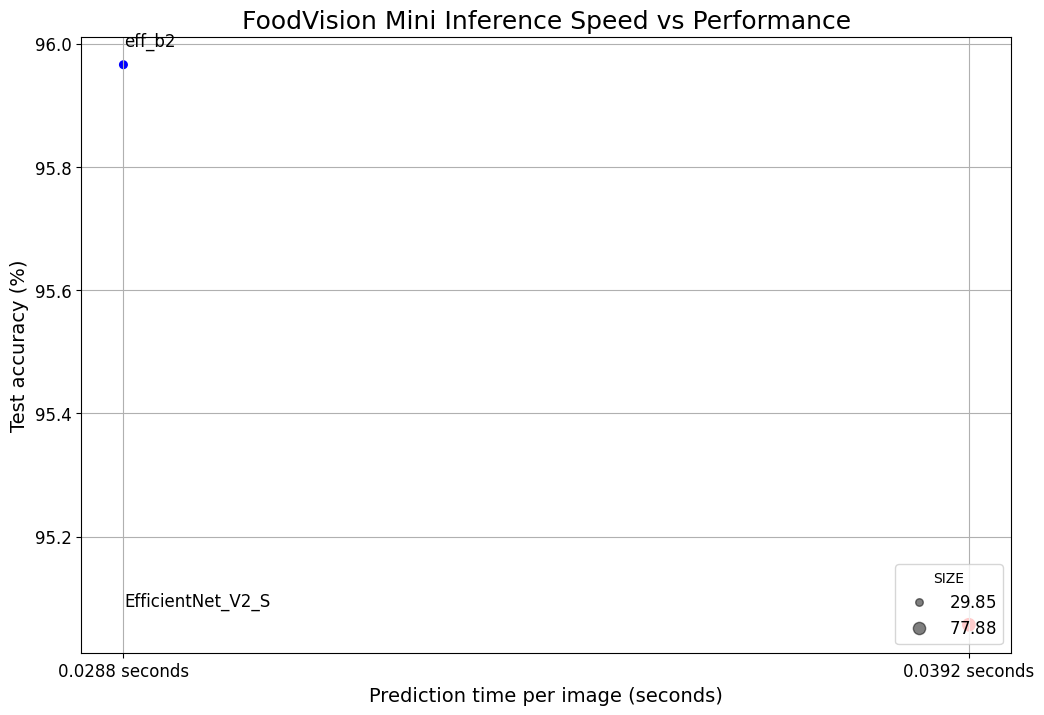

In [131]:
# I COPIED THIS
# 1. Create a plot from model comparison DataFrame
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(data=df,
                     x="AVERAGE_TIME",
                     y="ACCURACY",
                     c=["blue", "red"],
                     s="SIZE")

# 2. Add titles and labels to make our plot look good
ax.set_title("FoodVision Mini Inference Speed vs Performance", fontsize=18)
ax.set_xlabel("Prediction time per image (seconds)", fontsize=14)
ax.set_ylabel("Test accuracy (%)", fontsize=14)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True)

# 3. Annotate the samples on the scatter plot so we know what's going on.
for index, row in df.iterrows():
  ax.annotate(text=row["09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth"], # note: in some versions of Matplotlib, this may need to be "text" rather than "s"
              xy=(float(row["AVERAGE_TIME"][0])+0.0006, row["ACCURACY"]+0.03),
              size=12)

# 4. Create a legend based on the model sizes (model_size (MB)).
handles, labels = scatter.legend_elements(prop="sizes", alpha=0.5)
model_size_legend = ax.legend(handles,
                              labels,
                              loc="lower right",
                              title="SIZE",
                              fontsize=12)

# Save the figure
plt.savefig("09-foodvision-mini-inference-speed-vs-performance.png")

#  *NOW IT IS TIME TO DEPLOY THE MODEL , LET'S GO.........."*

In [9]:
try:
    import gradio as gr
except:
    !pip -q install gradio
    import gradio as gr


In [10]:
#LOADING THE MODEL BECAUSE I HAVE TERMINATED THE NOTEBOOK AT NIGHT
eff_b2_model,eff_b2_model_transform = create_eff_b2_model(3)
eff_b2_model.load_state_dict(torch.load(
    "../demos/food_vision_mini/09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth", weights_only=True))
#also get the classes
_,_,classes = data_setter_loader.data_setter_loader(train_dir, test_dir, eff_b2_model_transform, 32, 4)

In [11]:
#send model to cpu beacuse most of the devices that are going to make predictions on the 09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth are cpu so we standerize it.
eff_b2_model.to("cpu")
next(iter(eff_b2_model.parameters())).device

device(type='cpu')

### MAKING A FUNCTION THAT PREDICT IMAGE AND GIVE BACK THE PRED_PROBS AND TIME TAKEN
Let's create a function called predict() to go from:

images of food -> ML model (EffNetB2) -> outputs (food class label, prediction time)

In [12]:
def predict(image):
    start_time = timer()
    img_transformed = eff_b2_model_transform(image).unsqueeze(0)

    eff_b2_model.eval()
    with torch.inference_mode():
        pred_probs = torch.softmax(eff_b2_model(img_transformed), dim=1)

    #create pred probs dictionary
    pred_probs_dictionary = {classes[i]: float(pred_probs[0][i]) for i in range(len(classes))}

    end_time = timer()
    time_taken = end_time - start_time
    return pred_probs_dictionary,time_taken


In [13]:
#lets try it
random_image = random.sample(test_data_paths,1)[0]# 1-->test_data_paths, we made it previously , 2-->we make [0] because the random image taken from this is inside a list
img = Image.open(random_image)
preds , time = predict(img)
preds , time

({'pizza': 0.049604758620262146,
  'steak': 0.13909976184368134,
  'sushi': 0.8112955093383789},
 0.055689349999966)

### MAKING A LIST OF EXAMPLE IMAGES
The examples for Gradio can be created with the examples parameter

In [14]:
example_list = [[str(path)] for path in random.sample(test_data_paths,3)]# we put here str_name in list because gradio takes input as lists
example_list

[['../data/food_20_percent/test/pizza/2782998.jpg'],
 ['../data/food_20_percent/test/pizza/148765.jpg'],
 ['../data/food_20_percent/test/steak/2315011.jpg']]

### building gradio interface
Let's use gr.Interface() to go from:

input: image -> transform -> predict with EffNetB2 -> output: pred, prob prob, time

In [15]:
import gradio as gr

In [22]:
# Create title, description and article
title = "FoodVision Mini 🍕🥩🍣"
description = "An [EfficientNetB2 feature extractor](https://pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b2.html#torchvision.models.efficientnet_b2) computer vision model to classify images as pizza, steak or sushi."
article = "Created at [09. PyTorch Model Deployment](https://www.learnpytorch.io/09_pytorch_model_deployment/#74-building-a-gradio-interface)."
# create gradio demo
demo = gr.Interface(fn=predict,
                    inputs=gr.Image(type="pil"),
                    outputs=[gr.Label(num_top_classes=3,label="prediction"),
                             gr.Number(label="prediction time (seconds)")],
                    examples=example_list,
                    description=description,
                    title=title,
                    article=article)
#launch
demo.launch(debug=False,
            share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://681c7f1a95d8ae4be8.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# *PERFECT WE MADE IT DEPLOYED BUT IT WILL EXPIRE IN 7 DAYS,*
 *SO TO MAKE IT PERMENANT WE NEED TO PREPARE THE FILES SO THAT WE CAN MAKE IT PERMENANT ON THE HUGGING FACE*
 Let's start to put all of our app files into a single directory:

Colab -> folder with all Gradio files -> upload app files to Hugging Face Spaces -> deploy
By the end our file structure will look like this:

    demos/
    └── foodvision_mini/
        ├── 09_pretrained_effnetb2_feature_extractor_pizza_steak_sushi_20_percent.pth
        ├── app.py
        ├── examples/
        │   ├── example_1.jpg
        │   ├── example_2.jpg
        │   └── example_3.jpg
        ├── model.py
        └── requirements.txt
Why use this structure?

Because it's one of the simplest we could start with.

In [16]:
import shutil
#make a demo path
food_vision_mini_demo_path =Path("demos/food_vision_mini/")# we have put (/) at the end to tell explicitly that it is a folder and in both cases if we put it or not python is going to remove it from there if we put it and make the name of the file(folder)-->("demos/food_vision_mini")

#remove the AI_course that can exist in this directory and create a new directory
if food_vision_mini_demo_path.exists():
    shutil.rmtree(food_vision_mini_demo_path)
    food_vision_mini_demo_path.mkdir(exist_ok=True, parents=True)
else:
    food_vision_mini_demo_path.mkdir(exist_ok=True, parents=True)

make the examples--> get it from the test_dir

In [17]:
#make dir
food_vision_mini_examples_path = food_vision_mini_demo_path/"examples"
food_vision_mini_examples_path.mkdir(exist_ok=True, parents=True)
#get examples
food_vision_mini_examples = random.sample(test_data_paths,3)

In [18]:
food_vision_mini_examples

[PosixPath('../data/food_20_percent/test/pizza/3375083.jpg'),
 PosixPath('../data/food_20_percent/test/pizza/1555015.jpg'),
 PosixPath('../data/food_20_percent/test/pizza/482858.jpg')]

In [19]:
food_vision_mini_examples[0],food_vision_mini_examples[0].name

(PosixPath('../data/food_20_percent/test/pizza/3375083.jpg'), '3375083.jpg')

In [20]:
#copy the three images to the examples directory
for example in food_vision_mini_examples:
    destination = food_vision_mini_examples_path/example.name
    print(f"[INFO] coping {example} to {destination}")
    shutil.copy(src=example,dst=destination)

[INFO] coping ../data/food_20_percent/test/pizza/3375083.jpg to demos/food_vision_mini/examples/3375083.jpg
[INFO] coping ../data/food_20_percent/test/pizza/1555015.jpg to demos/food_vision_mini/examples/1555015.jpg
[INFO] coping ../data/food_20_percent/test/pizza/482858.jpg to demos/food_vision_mini/examples/482858.jpg


In [21]:
import os

In [22]:
#get the examples in a list of lists form for our  gradio i think
food_vision_mini_examples_list = [[example] for example in os.listdir(food_vision_mini_examples_path)]
food_vision_mini_examples_list

[['3375083.jpg'], ['482858.jpg'], ['1555015.jpg']]

In [23]:
#we need more in the name
food_vision_mini_examples_list = [["examples/"+example] for example in os.listdir(food_vision_mini_examples_path)]
food_vision_mini_examples_list

[['examples/3375083.jpg'], ['examples/482858.jpg'], ['examples/1555015.jpg']]

### MOVING THE TRAINED MODEL TO THE DEMO DIRECTORY

In [24]:
eff_b2_model_trained_path = "./models/09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth"
eff_b2_model_trained_path_destination = food_vision_mini_demo_path/eff_b2_model_trained_path.split("/")[2]

#try to do it
try:
    print(f"[INFO] trying to move {eff_b2_model_trained_path} to {eff_b2_model_trained_path_destination}")
    shutil.move(eff_b2_model_trained_path,eff_b2_model_trained_path_destination)
    print(f"[INFO] Model move complete.")
except:
    print(f"[INFO] No model found at {eff_b2_model_trained_path_destination}, perhaps its already been moved?")
    print(f"[INFO] Model exists at {eff_b2_model_trained_path_destination}: {eff_b2_model_trained_path_destination.exists()}")

[INFO] trying to move ./models/09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth to demos/food_vision_mini/09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth
[INFO] No model found at demos/food_vision_mini/09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth, perhaps its already been moved?
[INFO] Model exists at demos/food_vision_mini/09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth: False


In [25]:
eff_b2_model.load_state_dict(torch.load(
    "../demos/food_vision_mini/09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth", weights_only=True))

<All keys matched successfully>

### TURNING THE MODEL INTO PYTHIN SCRIPT

In [35]:
%%writefile ../demos/food_vision_mini/model.py
import torchvision
from torch import nn
def create_eff_b2_model (num_classes):
    eff_b2_model_weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT

    eff_b2_model_transform = eff_b2_model_weights.transforms()

    eff_b2_model = torchvision.models.efficientnet_b2(weights=eff_b2_model_weights)

    for param in eff_b2_model.parameters():
        param.requires_grad = False

    eff_b2_model.classifier = nn.Sequential(
    nn.Dropout(p=0.3,inplace=True),
    nn.Linear(in_features=1408, out_features=num_classes))

    return eff_b2_model , eff_b2_model_transform

Overwriting ../demos/food_vision_mini/model.py


## TURNING ALL OF THIS FILES INTO A GRADIO APP.PY FILE IN THE SAME DIRECTORY

In [36]:
%%writefile ../demos/food_vision_mini/app.py
import gradio as gr
import os
import torch

from finished_stuff.demos.food_vision_mini.model import create_eff_b2_model

#make the classes
classes = ["pizza","steak","sushi"]
#make the model and the transformer
eff_b2_model , eff_b2_model_transform = create_eff_b2_model(num_classes=len(classes))
#load the model
eff_b2_model.state_dict(torch.load(f="./09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth",map_location=torch.device("cpu")))
#make the prediction function
def predict(image):
    start_time = timer()
    img_transformed = eff_b2_model_transform(image).unsqueeze(0)

    eff_b2_model.eval()
    with torch.inference_mode():
        pred_probs = torch.softmax(eff_b2_model(img_transformed), dim=1)

    #create pred probs dictionary
    pred_probs_dictionary = {classes[i]: float(pred_probs[0][i]) for i in range(len(classes))}

    end_time = timer()
    time_taken = end_time - start_time
    return pred_probs_dictionary,time_taken


### 4. Gradio app ###

# Create title, description and article
title = "FoodVision Mini 🍕🥩🍣"
description = "An [EfficientNetB2 feature extractor](https://pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b2.html#torchvision.models.efficientnet_b2) computer vision model to classify images as pizza, steak or sushi."
article = "Created at [09. PyTorch Model Deployment]."
#make example list
example_list = [["examples/"+example for example in os.listdir("examples")]]
#make the interface
demo = gr.Interface(fn=predict, # maps inputs to outputs
                    inputs=gr.Image(type="pil"),
                    outputs=[gr.Label(num_top_classes=3, label="Predictions"),
                             gr.Number(label="Prediction time (s)")],
                    examples=example_list,
                    title=title,
                    description=description,
                    article=article)
#launch it
demo.launch()

Overwriting ../demos/food_vision_mini/app.py


### MAKE A REQUIRMENT FILE

In [37]:
%%writefile ../demos/food_vision_mini/requirements.txt
torch==2.6.0
torchvision==0.21.0
gradio>=4.0

Overwriting ../demos/food_vision_mini/requirements.txt


### Downloading our FoodVision Mini app files
We want to download our foodvision_mini demo app so we can upload it to Hugging Face Spaces.

In [26]:
!ls ../demos/food_vision_mini/examples

2903621.jpg  3785667.jpg  804460.jpg


In [27]:
#make it a zip file
!cd ../demos/food_vision_mini && zip -r ../food_mini.zip * -x "*.pyc" "*.ipynb" "*__pycache__*" "*ipynb_checkpoints*"

  adding: 09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth (deflated 8%)
  adding: app.py (deflated 53%)
  adding: examples/ (stored 0%)
  adding: examples/3785667.jpg (deflated 0%)
  adding: examples/2903621.jpg (deflated 0%)
  adding: examples/804460.jpg (deflated 1%)
  adding: food_mini.zip (stored 0%)
  adding: model.py (deflated 53%)
  adding: requirements.txt (deflated 7%)


we have made it work in the terminal of pycharm and it was running


# *LETS GO AND MAKE THE POTENTIALLY THE BEST MODEL WE ARE GOING TO MAKE AND WE CAN PLAY WITH SOME MODELS AND WE ARE GOING TO MAKE THE FINAL BIG THING **THE FULL FOOD DATASET***

In [28]:
# we have our train and test dir of the 20% ready for the experimenting
train_dir,test_dir

('../data/food_20_percent/train', '../data/food_20_percent/test')

In [42]:
weights=torchvision.models.EfficientNet_V2_L_Weights.DEFAULT
transform = weights.transforms()
model = torchvision.models.efficientnet_v2_l(weights=weights)

Downloading: "https://download.pytorch.org/models/efficientnet_v2_l-59c71312.pth" to /home/seif/.cache/torch/hub/checkpoints/efficientnet_v2_l-59c71312.pth
100%|██████████| 455M/455M [04:37<00:00, 1.72MB/s] 


In [43]:
model.classifier

Sequential(
  (0): Dropout(p=0.4, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

In [29]:
def create_eff_v2_l(num_classes):
    weights=torchvision.models.EfficientNet_V2_L_Weights.DEFAULT
    transform = weights.transforms()
    model = torchvision.models.efficientnet_v2_l(weights=weights)

    for param in model.parameters():
        param.requires_grad = False

    model.classifier= nn.Sequential(
        nn.Dropout(p=0.4,inplace=True),
        nn.Linear(in_features=1280, out_features=num_classes,bias=True)
    )

    return  model  , transform

In [30]:
classes

['pizza', 'steak', 'sushi']

In [31]:
eff_v2_l_model , eff_v2_l_transformer = create_eff_v2_l(len(classes))

In [48]:
summary(eff_v2_l_model,
        input_size=(1,3,224,224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 3]               --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1280, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    (864)                False
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    (64)                 False
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 3

In [32]:
#make the Data
eff_v2_l_train_dataloader , eff_v2_l_test_dataloader , _ = data_setter_loader.data_setter_loader(train_dir, test_dir, eff_v2_l_transformer, 32, 4)

In [33]:
#set the loss and optim
optimizer=torch.optim.Adam(params=eff_v2_l_model.parameters(),lr=0.001)
loss_fn = nn.CrossEntropyLoss()

In [34]:
device

'cuda'

In [51]:
eff_v2_l_results = trainer.training_fn(eff_v2_l_model, eff_v2_l_train_dataloader, eff_v2_l_test_dataloader, loss_fn, optimizer, 10, device)

 10%|█         | 1/10 [00:21<03:17, 21.93s/it]

Epoch: 1 | Train loss: 1.0011 | Train acc: 51.2500 | Test loss: 0.6036 | Test acc: 88.1250


 20%|██        | 2/10 [00:42<02:49, 21.14s/it]

Epoch: 2 | Train loss: 0.6131 | Train acc: 83.7500 | Test loss: 0.4379 | Test acc: 96.8750


 30%|███       | 3/10 [01:02<02:25, 20.84s/it]

Epoch: 3 | Train loss: 0.5265 | Train acc: 82.5000 | Test loss: 0.3601 | Test acc: 94.7159


... (10 outputs left out)

 90%|█████████ | 9/10 [03:04<00:20, 20.19s/it]

Epoch: 9 | Train loss: 0.3306 | Train acc: 88.3333 | Test loss: 0.2138 | Test acc: 96.5909


100%|██████████| 10/10 [03:24<00:00, 20.45s/it]

Epoch: 10 | Train loss: 0.3065 | Train acc: 89.5833 | Test loss: 0.1924 | Test acc: 96.5909


In [56]:
model_saver.model_saver(eff_v2_l_model, "../../models", "FINAL_COMPARE_MODEL_.pth")

saving model to ../models/FINAL_COMPARE_MODEL_.pth


In [35]:
#load the model because i have terminated it and i have closed the app
eff_v2_l_model.load_state_dict(torch.load("../../models/FINAL_COMPARE_MODEL_.pth", map_location=torch.device(device)))

<All keys matched successfully>

In [36]:
eff_v2_l_sum_param = sum(torch.numel(param) for param in eff_v2_l_model.parameters())
eff_v2_l_sum_param

117238115

In [37]:
eff_v2_l_model_size = Path("../../models/FINAL_COMPARE_MODEL_.pth").stat().st_size // (1024 ** 2)
print(f"{eff_v2_l_model_size} MB")

449 MB


In [ ]:
eff_v2_l_stats = {"ACCURACY" : round(eff_v2_l_results["test_acc"][-1]*100,3),
                           "LOSS": round(eff_v2_l_results["test_loss"][-1],3),
                           "SIZE": round(eff_v2_l_model_size,2),
                           "PARAM": round(eff_v2_l_sum_param,2)}

In [72]:
eff_b2_model_stats={'ACCURACY': 95.966,
 'LOSS': 0.302,
 'SIZE': 29.85,
 'PARAM': 7705221}

In [76]:
df = pd.DataFrame([eff_v2_l_stats,eff_b2_model_stats])
df["models"]=["eff_v2_l","eff_b2"]
df

,ACCURACY,LOSS,SIZE,PARAM,models
0,96.591,0.192,449.00,117238115,eff_v2_l
1,95.966,0.302,29.85,7705221,eff_b2


# lets test which of them is better on the full dataset

In [46]:
#make this class---> to make a transform of any dataset (not single image) that i put in it's input << it is not instant transform because this would break the hardware it is that whenever it is called it makes the transform for what is called , but we simply say it makes full transform for the full dataset>>
class TransformDataset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, index):
        img, label = self.subset[index]  # Gets ONE raw PIL image
        if self.transform:
            img = self.transform(img)    # Converts to tensor
        return img, label

In [47]:
eff_v2_l_model_food101 , eff_v2_l_transformer_food101 = create_eff_v2_l(101)
eff_b2_model_food101 , eff_b2_transformer_food101 = create_eff_b2_model(101)
#send to device
eff_v2_l_model_food101 = eff_v2_l_model_food101.to(device)
eff_b2_model_food101 = eff_b2_model_food101.to(device)

In [48]:
#because we are working with a big dataset we are going to make some Data augmentation for the train Data
eff_v2_l_train_transformer_food101=torchvision.transforms.Compose([
    torchvision.transforms.TrivialAugmentWide(),
    eff_v2_l_transformer_food101
])
eff_b2_train_transformer_food101 = torchvision.transforms.Compose([
    torchvision.transforms.TrivialAugmentWide(),
    eff_b2_transformer_food101
])

In [49]:
eff_b2_train_transformer_food101

Compose(
    TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
    ImageClassification(
    crop_size=[288]
    resize_size=[288]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)
)

In [50]:
eff_b2_train_transformer_food101

Compose(
    TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
    ImageClassification(
    crop_size=[288]
    resize_size=[288]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)
)

getting the data

In [51]:
#getting the Data
from torchvision import datasets

data_path = Path("../data")
food101_train_data = datasets.Food101(root=data_path,
                                      split='train',
                                      transform=None,
                                      download=True)
food101_test_data = datasets.Food101(root=data_path,
                                     split='test',
                                     transform=None,
                                     download=True)

In [52]:
# MAKING A FUNCTION FOR MAKING SPLITS OF DATA so -->so that for instance we can get 20% of the Data
def make_data_splits (dataset,fraction,transform=None):
    len_1 = int(len(dataset)*fraction)
    len_2 = len(dataset) - len_1

    print(f"[INFO] Splitting dataset of length {len(dataset)} into splits of size: {len_1} and {len_2}")

    random_split_1 , random_split_2 = torch.utils.data.random_split(dataset,
                                                                    lengths=[len_1, len_2])
    if transform:
        random_split_1  = TransformDataset(random_split_1,transform)# we are making only for the 1 because we only need the first one
    return random_split_1 , random_split_2

In [53]:
train_data_food101_20_percent , _ = make_data_splits(food101_train_data,0.2)
test_data_food101_20_percent , _ = make_data_splits(food101_test_data,0.2)

[INFO] Splitting dataset of length 75750 into splits of size: 15150 and 60600
[INFO] Splitting dataset of length 25250 into splits of size: 5050 and 20200


In [54]:
from torch.utils.data import DataLoader
BATCH_SIZE =32
NUM_WORKERS = 4

#make the eff_b2 transformed dataset
#train
train_data_food101_20_percent_eff_b2_transform = TransformDataset(train_data_food101_20_percent,
                                                                  eff_b2_train_transformer_food101)
#test
test_data_food101_20_percent_eff_b2_transform = TransformDataset(test_data_food101_20_percent,
                                                                 eff_b2_transformer_food101)
#make the eff_b2 transformed dataloader
#train
eff_b2_train_dataloader_food101_20_percent = DataLoader(
    train_data_food101_20_percent_eff_b2_transform,
    BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS)
#test
eff_b2_test_dataloader_food101_20_percent = DataLoader(
    test_data_food101_20_percent_eff_b2_transform,
    BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS)


#make the eff_v2_l transformed dataset
#train
train_data_food101_20_percent_eff_v2_l_transform = TransformDataset(train_data_food101_20_percent,
                                                                eff_v2_l_train_transformer_food101)
#test
test_data_food101_20_percent_eff_v2_l_transform = TransformDataset(test_data_food101_20_percent,
                                                                   eff_v2_l_transformer_food101)
#make the eff_v2_l transformed dataloader
#train
eff_v2_l_train_dataloader_food101_20_percent = DataLoader(
    train_data_food101_20_percent_eff_v2_l_transform,
    16,  #becasue the eff_v2_l model is huge the 32 batch can make the gpu out of memory
    shuffle=True,
    num_workers=NUM_WORKERS)
#test
eff_v2_l_test_dataloader_food101_20_percent = DataLoader(
    test_data_food101_20_percent_eff_v2_l_transform,
    16,
    shuffle=False,
    num_workers=NUM_WORKERS)

In [55]:
#train the eff_b2_food101_model
#optim,loss_fn
optimizer =torch.optim.Adam(params=eff_b2_model_food101.parameters(),lr=0.001)
loss_fn = nn.CrossEntropyLoss()
#train
eff_b2_model_food101_results = trainer.training_fn(eff_b2_model_food101,
                                                   eff_b2_train_dataloader_food101_20_percent,
                                                   eff_b2_test_dataloader_food101_20_percent,
                                                   loss_fn,
                                                   optimizer,
                                                   10,
                                                   device)

 10%|█         | 1/10 [00:57<08:40, 57.80s/it]

Epoch: 1 | Train loss: 3.4889 | Train acc: 27.3593 | Test loss: 2.4455 | Test acc: 49.1054


 20%|██        | 2/10 [01:55<07:42, 57.85s/it]

Epoch: 2 | Train loss: 2.4816 | Train acc: 44.0429 | Test loss: 2.0231 | Test acc: 53.8020


 30%|███       | 3/10 [02:53<06:44, 57.73s/it]

Epoch: 3 | Train loss: 2.2107 | Train acc: 47.7321 | Test loss: 1.8424 | Test acc: 55.9625


... (10 outputs left out)

 90%|█████████ | 9/10 [08:36<00:57, 57.25s/it]

Epoch: 9 | Train loss: 1.7519 | Train acc: 56.0240 | Test loss: 1.6363 | Test acc: 58.2963


100%|██████████| 10/10 [09:33<00:00, 57.37s/it]

Epoch: 10 | Train loss: 1.7433 | Train acc: 56.7143 | Test loss: 1.6257 | Test acc: 58.4104


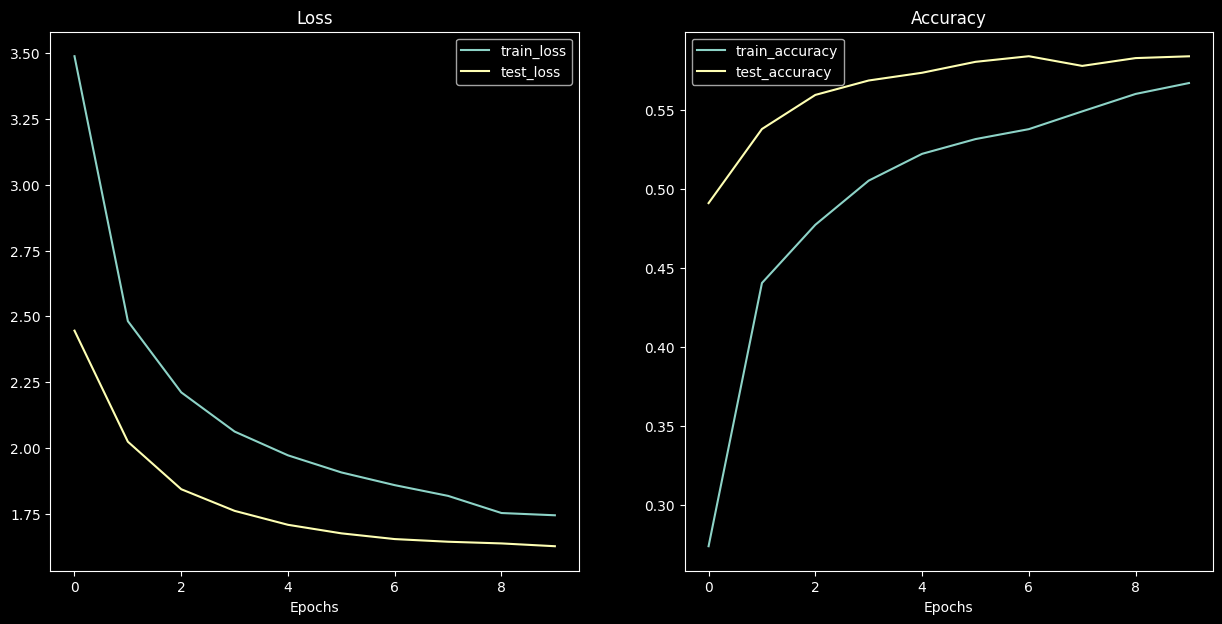

In [56]:
plot_loss_curves.plot_loss_curves(eff_b2_model_food101_results)

In [57]:
#making a function that gets us the total params of the model and the size of the model , becuase the size is the (param_num*4(each param is float32(32bits)(4bytes)) byte , then /(1024**2) --> to get the size in MB
def get_model_param_and_size (model):
    param_num = sum(torch.numel(param) for param in model.parameters())
    model_size = (param_num*4)/(1024**2)
    return param_num,model_size

In [58]:
#get the params and size of the eff_b2_food101_model
eff_b2_model_food101_total_param , eff_b2_model_food101_size = get_model_param_and_size(eff_b2_model_food101)

In [59]:
#from gemini --> free memory after training one model to avoid any memory error
import gc

# Free up memory after eff_b2 finishes training
gc.collect()
torch.cuda.empty_cache()

In [60]:
#train the eff_v2_l_food101_model
#optim,loss_fn
optimizer =torch.optim.Adam(params=eff_v2_l_model_food101.parameters(),lr=0.001)
loss_fn = nn.CrossEntropyLoss()
#train
eff_v2_l_model_food101_results = trainer.training_fn(eff_v2_l_model_food101,
                                                     eff_v2_l_train_dataloader_food101_20_percent,
                                                     eff_v2_l_test_dataloader_food101_20_percent,
                                                     loss_fn,
                                                     optimizer,
                                                     10,
                                                     device)

 10%|█         | 1/10 [09:54<1:29:12, 594.70s/it]

Epoch: 1 | Train loss: 3.3064 | Train acc: 27.1685 | Test loss: 1.7202 | Test acc: 62.9866


 20%|██        | 2/10 [19:45<1:18:57, 592.15s/it]

Epoch: 2 | Train loss: 2.4226 | Train acc: 43.1089 | Test loss: 1.3253 | Test acc: 68.2991


 30%|███       | 3/10 [29:44<1:09:27, 595.34s/it]

Epoch: 3 | Train loss: 2.2879 | Train acc: 46.1108 | Test loss: 1.2245 | Test acc: 69.3790


... (10 outputs left out)

 90%|█████████ | 9/10 [1:29:32<09:59, 599.27s/it]

Epoch: 9 | Train loss: 2.1621 | Train acc: 50.4346 | Test loss: 1.0584 | Test acc: 72.3853


100%|██████████| 10/10 [1:39:42<00:00, 598.21s/it]

Epoch: 10 | Train loss: 2.1633 | Train acc: 50.7863 | Test loss: 1.0571 | Test acc: 72.0016


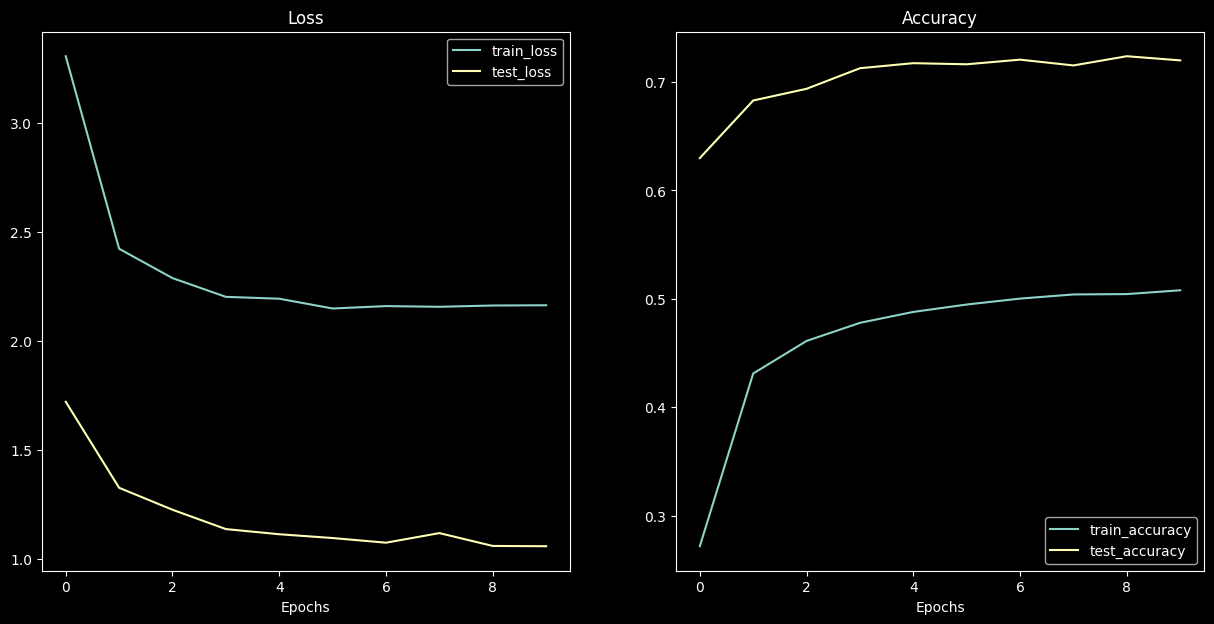

In [61]:
plot_loss_curves.plot_loss_curves(eff_v2_l_model_food101_results)

In [62]:
#get the param and size of the eff_v2_l_model_food101
eff_v2_l_model_food101_total_param , eff_v2_l_model_food101_size = get_model_param_and_size(eff_v2_l_model_food101)

In [63]:
#make dictionary for both models for tracking
#eff_b2_model_food101
eff_b2_model_food101_stats={"ACCURACY" : round(eff_b2_model_food101_results["test_acc"][-1]*100,3),
                           "LOSS": round(eff_b2_model_food101_results["test_loss"][-1],3),
                           "SIZE": round(eff_b2_model_food101_size,2),
                           "PARAM":  f"{eff_b2_model_food101_total_param:,}"}
#eff_v2_l_model_food101
eff_v2_l_model_food101_stats = {"ACCURACY" : round(eff_v2_l_model_food101_results["test_acc"][-1]*100,3),
                           "LOSS": round(eff_v2_l_model_food101_results["test_loss"][-1],3),
                           "SIZE": round(eff_v2_l_model_food101_size,2),
                           "PARAM":  f"{eff_v2_l_model_food101_total_param:,}"}

In [65]:
#make a DataFrame for comparing
import pandas as pd
df = pd.DataFrame([eff_b2_model_food101_stats,eff_v2_l_model_food101_stats])
df["models"] = ["eff_b2_model_food101","eff_v2_l_model_food101"]
df

,ACCURACY,LOSS,SIZE,PARAM,models
0,58.410,1.626,29.92,"7,843,303",eff_b2_model_food101
1,72.002,1.057,447.71,"117,363,653",eff_v2_l_model_food101


### alright we can see that the eff_b2 is a much better trade off

.










.

# ***FINALE:***
# now lets go and make more training for the eff_b2 model and train it on **THE FULL FOOD101 DATASET**

In [86]:
final_eff_b2_model , final_eff_b2_trasnformer = create_eff_b2_model(101)
final_eff_b2_model=final_eff_b2_model.to(device)

In [87]:
summary(final_eff_b2_model,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 101]             --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1408, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    (864)                False
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    (64)                 False
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 1

In [88]:
final_eff_b2_train_trasnformer=transforms.Compose([
    transforms.TrivialAugmentWide(),
    final_eff_b2_trasnformer
])

In [89]:
#make the transform for the full food101_train_dataset
food101_train_data_transformed = TransformDataset(food101_train_data,final_eff_b2_train_trasnformer)
food101_test_data_transformed = TransformDataset(food101_test_data,final_eff_b2_trasnformer)
#making the dataloader
NUM_WORKERS=4
BATCH_SIZE=32
food101_train_data_transformed_dataloader = DataLoader(food101_train_data_transformed,
                                                       BATCH_SIZE,
                                                       shuffle=True,
                                                       num_workers=NUM_WORKERS)
food101_test_data_transformed_dataloader = DataLoader(food101_test_data_transformed,
                                                      BATCH_SIZE,
                                                      shuffle=False,
                                                      num_workers=NUM_WORKERS)

In [90]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(final_eff_b2_model.parameters(),lr=0.001)

In [91]:
device

'cuda'

In [92]:
#make the training loop for the training
final_eff_b2_model_results = trainer.training_fn(final_eff_b2_model,
                                                 food101_train_data_transformed_dataloader,
                                                 food101_test_data_transformed_dataloader,
                                                 loss_fn,
                                                 optimizer,
                                                 5,
                                                 device)

 20%|██        | 1/5 [05:09<20:37, 309.39s/it]

Epoch: 1 | Train loss: 2.6149 | Train acc: 40.5058 | Test loss: 1.5892 | Test acc: 61.0206


 40%|████      | 2/5 [10:06<15:07, 302.34s/it]

Epoch: 2 | Train loss: 2.1385 | Train acc: 48.2589 | Test loss: 1.4730 | Test acc: 62.4881


 60%|██████    | 3/5 [15:10<10:05, 302.97s/it]

Epoch: 3 | Train loss: 2.0693 | Train acc: 49.5324 | Test loss: 1.4185 | Test acc: 63.6709


 80%|████████  | 4/5 [20:20<05:05, 305.93s/it]

Epoch: 4 | Train loss: 2.0491 | Train acc: 50.0356 | Test loss: 1.3733 | Test acc: 64.8180


100%|██████████| 5/5 [25:28<00:00, 305.75s/it]

Epoch: 5 | Train loss: 2.0330 | Train acc: 50.2842 | Test loss: 1.3712 | Test acc: 64.5372


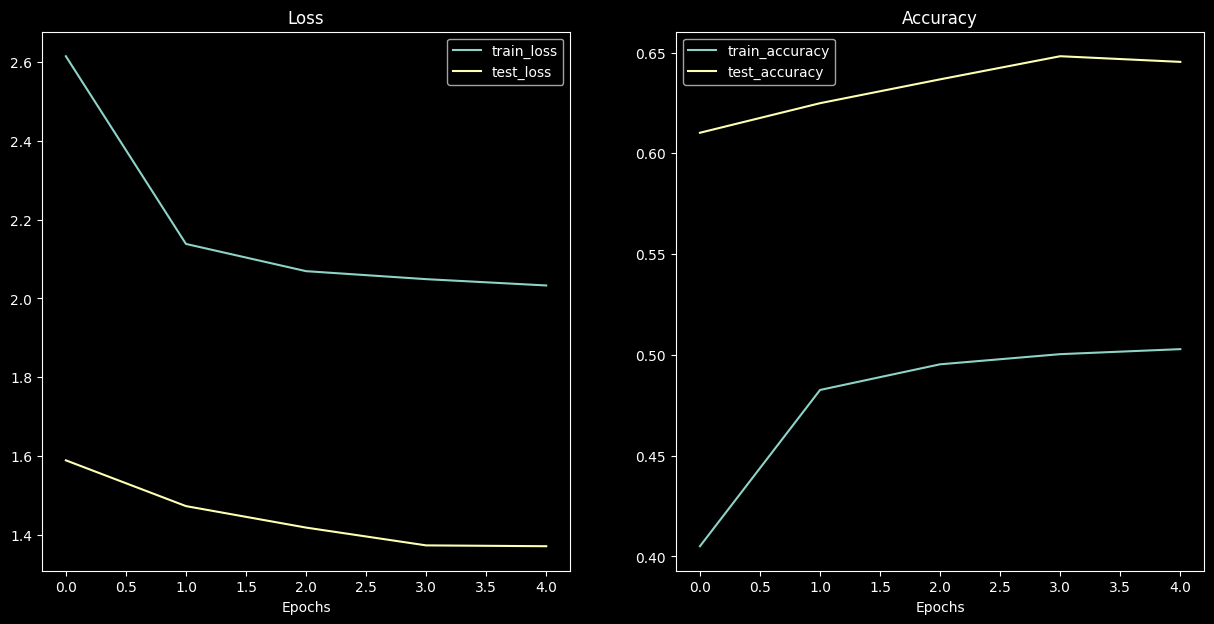

In [94]:
plot_loss_curves.plot_loss_curves(final_eff_b2_model_results)

In [93]:
final_eff_b2_model_results_2 = trainer.training_fn(final_eff_b2_model,
                                                   food101_train_data_transformed_dataloader,
                                                   food101_test_data_transformed_dataloader,
                                                   loss_fn,
                                                   optimizer,
                                                   5,
                                                   device)

 20%|██        | 1/5 [05:11<20:45, 311.28s/it]

Epoch: 1 | Train loss: 2.0203 | Train acc: 50.8015 | Test loss: 1.3517 | Test acc: 65.1741


 40%|████      | 2/5 [10:06<15:06, 302.05s/it]

Epoch: 2 | Train loss: 2.0293 | Train acc: 50.3924 | Test loss: 1.3648 | Test acc: 64.4264


 60%|██████    | 3/5 [15:04<10:00, 300.22s/it]

Epoch: 3 | Train loss: 2.0134 | Train acc: 50.7808 | Test loss: 1.3728 | Test acc: 64.2959


 80%|████████  | 4/5 [20:09<05:01, 301.89s/it]

Epoch: 4 | Train loss: 2.0148 | Train acc: 50.7738 | Test loss: 1.3275 | Test acc: 65.2492


100%|██████████| 5/5 [25:18<00:00, 303.79s/it]

Epoch: 5 | Train loss: 2.0157 | Train acc: 50.8349 | Test loss: 1.3252 | Test acc: 65.3244


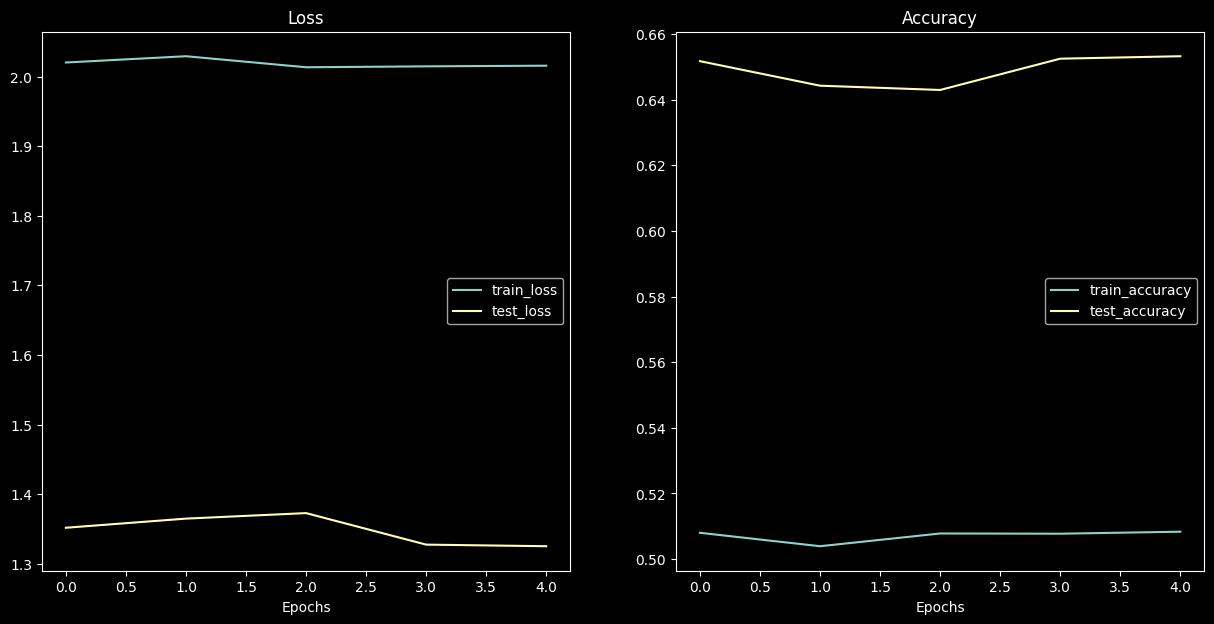

In [95]:
plot_loss_curves.plot_loss_curves(final_eff_b2_model_results_2)

In [108]:
# the model stopped learing so what we are going to make is that we are going to try to lower the lr
optimizer = torch.optim.Adam(final_eff_b2_model.parameters(),lr=0.0001)
final_eff_b2_model_results_3 = trainer.training_fn(final_eff_b2_model,
                                                   food101_train_data_transformed_dataloader,
                                                   food101_test_data_transformed_dataloader,
                                                   loss_fn,
                                                   optimizer,
                                                   5,
                                                   device)

 20%|██        | 1/5 [04:57<19:48, 297.00s/it]

Epoch: 1 | Train loss: 1.9295 | Train acc: 52.4133 | Test loss: 1.3220 | Test acc: 65.5142


 40%|████      | 2/5 [09:46<14:37, 292.42s/it]

Epoch: 2 | Train loss: 1.9150 | Train acc: 52.8782 | Test loss: 1.2997 | Test acc: 66.2777


 60%|██████    | 3/5 [14:39<09:45, 292.92s/it]

Epoch: 3 | Train loss: 1.9098 | Train acc: 52.7014 | Test loss: 1.3014 | Test acc: 66.1116


 80%|████████  | 4/5 [19:28<04:51, 291.11s/it]

Epoch: 4 | Train loss: 1.8952 | Train acc: 52.8861 | Test loss: 1.2814 | Test acc: 66.5190


100%|██████████| 5/5 [24:30<00:00, 294.09s/it]

Epoch: 5 | Train loss: 1.8992 | Train acc: 52.9693 | Test loss: 1.2988 | Test acc: 66.4122


In [109]:
model_saver.model_saver(final_eff_b2_model, "../../models/", "safe_save.pth")

saving model to ../models/safe_save.pth


In [110]:
#because the model is not improving we are going to unfreeze another layer
for param in final_eff_b2_model.features[-5:].parameters():
    param.requires_grad=True
#after any model change you should update the optimizer
optimizer = torch.optim.Adam(final_eff_b2_model.parameters(),lr=0.0001)

In [111]:
summary(final_eff_b2_model,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 101]             --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1408, 7, 7]      --                   Partial
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    (864)                False
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    (64)                 False
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1,

In [112]:
final_eff_b2_model_results_4 = trainer.training_fn(final_eff_b2_model,
                                                   food101_train_data_transformed_dataloader,
                                                   food101_test_data_transformed_dataloader,
                                                   loss_fn,
                                                   optimizer,
                                                   5,
                                                   device)

 20%|██        | 1/5 [08:00<32:00, 480.06s/it]

Epoch: 1 | Train loss: 1.3070 | Train acc: 66.3574 | Test loss: 0.6260 | Test acc: 82.4604


 40%|████      | 2/5 [15:48<23:40, 473.40s/it]

Epoch: 2 | Train loss: 0.9356 | Train acc: 74.9780 | Test loss: 0.5343 | Test acc: 84.8972


 60%|██████    | 3/5 [23:32<15:38, 469.00s/it]

Epoch: 3 | Train loss: 0.7646 | Train acc: 79.2225 | Test loss: 0.4981 | Test acc: 85.5696


 80%|████████  | 4/5 [31:18<07:47, 467.94s/it]

Epoch: 4 | Train loss: 0.6471 | Train acc: 82.0832 | Test loss: 0.4789 | Test acc: 86.3805


100%|██████████| 5/5 [39:00<00:00, 468.01s/it]

Epoch: 5 | Train loss: 0.5467 | Train acc: 84.6121 | Test loss: 0.4825 | Test acc: 86.5348


In [113]:
final_eff_b2_model_results_5 = trainer.training_fn(final_eff_b2_model,
                                                   food101_train_data_transformed_dataloader,
                                                   food101_test_data_transformed_dataloader,
                                                   loss_fn,
                                                   optimizer,
                                                   5,
                                                   device)

 20%|██        | 1/5 [07:38<30:34, 458.71s/it]

Epoch: 1 | Train loss: 0.4827 | Train acc: 86.3132 | Test loss: 0.4809 | Test acc: 86.7919


 40%|████      | 2/5 [15:16<22:55, 458.45s/it]

Epoch: 2 | Train loss: 0.4236 | Train acc: 87.8730 | Test loss: 0.4844 | Test acc: 86.9858


 60%|██████    | 3/5 [22:55<15:17, 458.56s/it]

Epoch: 3 | Train loss: 0.3844 | Train acc: 88.9160 | Test loss: 0.4825 | Test acc: 87.2745


 80%|████████  | 4/5 [30:32<07:37, 457.96s/it]

Epoch: 4 | Train loss: 0.3488 | Train acc: 89.8121 | Test loss: 0.4961 | Test acc: 87.0451


100%|██████████| 5/5 [38:09<00:00, 457.95s/it]

Epoch: 5 | Train loss: 0.3216 | Train acc: 90.6932 | Test loss: 0.5018 | Test acc: 87.1282


In [115]:
model_saver.model_saver(final_eff_b2_model, "../demos/food_vision_big_food101", "09_final_best_performing_model.pth")

saving model to ../demos/food_vision_big_food101/09_final_best_performing_model.pth


# now lets make a food vision mini file at the demos to deploy it

    demos/
      foodvision_big/
        09_pretrained_effnetb2_feature_extractor_food101_20_percent.pth
        app.py
        class_names.txt
        examples/
          example_1.jpg
        model.py
        requirements.txt

In [96]:
# as the pwd in the terminal but in the notebook
import os
print(os.getcwd())

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/AI_course


In [97]:
#make a directory
food_vision_big_food101_path = Path("../demos/food_vision_big_food101/")
food_vision_big_food101_path.mkdir(parents=True, exist_ok=True)
#make an examples directory
(food_vision_big_food101_path/"examples").mkdir(parents=True, exist_ok=True)

In [98]:
# as the pwd in the terminal but in the notebook
import os
print(os.getcwd())

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/AI_course


In [99]:
# Food101 saves to a directory too! ,So I can still use glob!
# after thinking ,instead of making huge list and then getting 3 images , why dont we get them by copy/paste because it is not something that is technical it is just for the users to try

#this is the list of list examples that gradio needs
examples_gradio= [["../Data/food-101/images/apple_pie/1011328.jpg"],["../Data/food-101/images/fish_and_chips/753322.jpg"],["../Data/food-101/images/nachos/2228627.jpg"]]

#this is list of strings for examples that are copied into the examples folder
examples_for_copy= ["../Data/food-101/images/apple_pie/1011328.jpg","../Data/food-101/images/fish_and_chips/753322.jpg","../Data/food-101/images/nachos/2228627.jpg"]

In [100]:
#copying images into the examples destination
for example in examples_for_copy :
    example = Path(example)
    destination = food_vision_big_food101_path/"examples"/example.name
    print(f"[INFO] coping {example} to {destination}")
    shutil.copy(src=example,dst=destination)

[INFO] coping ../data/food-101/images/apple_pie/1011328.jpg to ../demos/food_vision_big_food101/examples/1011328.jpg
[INFO] coping ../data/food-101/images/fish_and_chips/753322.jpg to ../demos/food_vision_big_food101/examples/753322.jpg
[INFO] coping ../data/food-101/images/nachos/2228627.jpg to ../demos/food_vision_big_food101/examples/2228627.jpg


In [102]:
#making the classes (we can copy paste from the Data file but we make it harder for sake of practise)
food101_classes = food101_train_data.classes    #we can also use the food101_test_data
with open(food_vision_big_food101_path/"class_names.txt","w") as f:
    print(f"[INFO] Saving Food101 class names to {food_vision_big_food101_path}/class_names.txt")
    f.write("\n".join(food101_classes)) #to make a new  line for every class

[INFO] Saving Food101 class names to ../demos/food_vision_big_food101/class_names.txt


In [105]:
# as the pwd in the terminal but in the notebook
import os
print(os.getcwd())

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/AI_course


In [106]:
%%writefile ../demos/food_vision_big_food101/model.py
#making the model.py folder
import torchvision

from torch import nn

def create_eff_b2_model (num_classes=3):#this 3 is a default that we can change it to 101 when we need to
    eff_b2_model_weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT

    eff_b2_model_transform = eff_b2_model_weights.transforms()

    eff_b2_model = torchvision.models.efficientnet_b2(weights=eff_b2_model_weights)

    for param in eff_b2_model.parameters():
        param.requires_grad = False

    eff_b2_model.classifier = nn.Sequential(
    nn.Dropout(p=0.3,inplace=True),
    nn.Linear(in_features=1408, out_features=num_classes))

    return eff_b2_model , eff_b2_model_transform

Writing ../demos/food_vision_big_food101/model.py


In [116]:
%%writefile ../demos/food_vision_big_food101/app.py#making the app.py file
### imports
import gradio as gr
import torch

from model import create_eff_b2_model # no problem if this import was red in the notebook because here we are dealing as we are in the demos/DEMO_NAME directory
from timeit import default_timer as timer

#set up classes names
with open("class_names.txt","r") as f:
    class_names = [food_name.strip() for food_name in f.readlines()] #what the strip does is that it removes the "\n" that is there to make a new line for every class

#make the model and the transformer
eff_b2_model , eff_b2_transformer = create_eff_b2_model(num_classes=101)
#laod the saved model
eff_b2_model.load_state_dict(torch.load("FINAL_MODEL_EFF_B2.pth",
                                        map_location=torch.device('cpu')))#load on cpu , because users mostly have cpu only
### predict funciton
def predict(img):
    start_time = timer()
    #
    img=eff_b2_transformer(img).unsqueeze(dim=0)
    #
    eff_b2_model.eval()
    with torch.inference_mode():
        pred_probs = torch.softmax(eff_b2_model(img), dim=1)
    #
    pred_labels_and_probs = {class_names[i]:float(pred_probs[0][i]) for i in range(len(class_names))} # remember has to be float for gradio
    #
    end_time=timer()
    time_taken = round(end_time-start_time,2)
    #
    return pred_labels_and_probs, time_taken


### 4. Gradio app ###

# Create title, description and article
title = "FoodVision BIG 🍔👁💪"
description = "based on 101 classes"
article = "Created with EfficientNetB2"
# Create example list
example_list = [
    ["examples/1011328.jpg"],
    ["examples/753322.jpg"],
    ["examples/2228627.jpg"]
]# that is becasue of some error that os.listdir makes so we made it manually

# Create the Gradio demo
demo = gr.Interface(fn=predict, # maps inputs to outputs
                  inputs=gr.Image(type="pil"),
                  outputs=[gr.Label(num_top_classes=5, label="Predictions"),
                          gr.Number(label="Prediction time (s)")],
                  examples=example_list,
                  title=title,
                  description=description,
                  article=article)

# Launch the demo!
demo.launch()


Writing ../demos/food_vision_big_food101/app.py


In [117]:
%%writefile ../demos/food_vision_big_food101/requirments.txt
#make the requirment files
torch==1.12.0
torchvision==0.13.0
gradio==3.1.4

Writing ../demos/food_vision_big_food101/requirments.txt


In [120]:
# as the pwd in the terminal but in the notebook
import os
print(os.getcwd())

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/AI_course


In [122]:
!cd ../demos/food_vision_big_food101 && zip -r ../foodvision_big.zip * -x "*.pyc" "*.ipynb" "*__pycache__*" "*ipynb_checkpoints*"

  adding: 09_final_best_performing_model.pth (deflated 8%)
  adding: app.py (deflated 55%)
  adding: class_names.txt (deflated 48%)
  adding: examples/ (stored 0%)
  adding: examples/1011328.jpg (deflated 1%)
  adding: examples/753322.jpg (deflated 0%)
  adding: examples/2228627.jpg (deflated 1%)
  adding: model.py (deflated 50%)
  adding: requirments.txt (deflated 5%)
